# Phase 3.5 — Execution validation and strategy diagnosis

Executed research notebook. This uses frozen Phase 3 outputs and executed Phase 3.5 experiments. All 24 evaluation windows have been examined before; exploratory variants are **not untouched out-of-sample evidence**. Currency is THB unless stated. The daily model is not the official IOC validator.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
rid = '20261027T174032Z'
candidates = [Path.cwd()/'research_set50_execution_validation'/'results'/rid,
              Path.cwd()/'research_set50_execution_validation'/'published_results'/rid,
              Path.cwd().parent/'results'/rid,
              Path.cwd().parent/'published_results'/rid,
              Path.cwd()/'results'/rid]
out = next(p for p in candidates if p.exists())
old = out.parents[2]/'research_set50_portfolio'/'published_results'/'20261027T162905Z_979c875c'
if not old.exists(): old = out.parents[2]/'research_set50_portfolio'/'results'/'20261027T162905Z_979c875c'
print('Experiment:', out.name)
print('Saved Phase 3:', old.exists())

Experiment: 20261027T174032Z
Saved Phase 3: True


## 1. Frozen Phase 3 reproduction

The comparison matches every saved row by window, role, strategy, scenario, and exit rule. A zero numerical difference proves deterministic reproduction under the same inputs; it does not validate executable prices.

In [2]:
r=json.loads((out/'phase3_reconciliation.json').read_text())
display(pd.DataFrame({'metric':list(r['max_absolute_difference']),
                      'maximum_absolute_difference':list(r['max_absolute_difference'].values())}))
print('Matched rows:',r['matched_rows'],'/',r['saved_rows'],'; tolerance:',r['tolerance'])
assert r['matched_rows']==r['saved_rows'] and max(r['max_absolute_difference'].values())<=r['tolerance']

,metric,maximum_absolute_difference
0,net_return,0.0
1,gross_return_proxy,0.0
2,benchmark_return,0.0
3,excess_return,0.0
4,commission_thb,0.0
5,vat_thb,0.0
6,slippage_thb,0.0
7,turnover,0.0
8,max_drawdown,0.0
9,average_exposure,0.0


Matched rows: 356 / 356 ; tolerance: 1e-10


## 2. Actual trading rules

A–E rank permitted, sufficiently complete stocks by **Momentum20 = Close(t)/Close(t−20) − 1**. Positive momentum is not required: −2% can rank above −5%. Six stocks are targeted. A/C use equal weights; B/D use inverse 20-day volatility. C/D use one-day reversal only as a close-rank tie breaker. E uses the development-selected A base, top-ten retention, 75% target exposure, 18% cap and a 3% weight-change threshold. Others target 80% exposure, 20% cap. Rebalance is every five sessions using the prior completed close, with modeled next-open execution. The separate SMA20/SMA60 experiment is not A–E.

Commission is 0.157% per filled side, VAT is 7% of commission, quantities use 100-share lots, and the daily model applies one adverse tick and a 1% trailing-volume participation cap. FIFO counts a buy lot only after it is fully closed. See the [rulebook](../docs/01_strategy_rulebook.md) for missing-data and accounting details.

## 3. Daily prices against raw ticks

The overlap covers 16 sessions. Auction prints are used for open and close. A matching OHLC is evidence about this overlap only; historical corporate-action factors and quote depth remain unavailable.

,stock_days,all_OHLC_match,missing_open_auction,missing_close_auction,globally_sorted_tick_files,tick_files
0,768,768,0,0,0,16


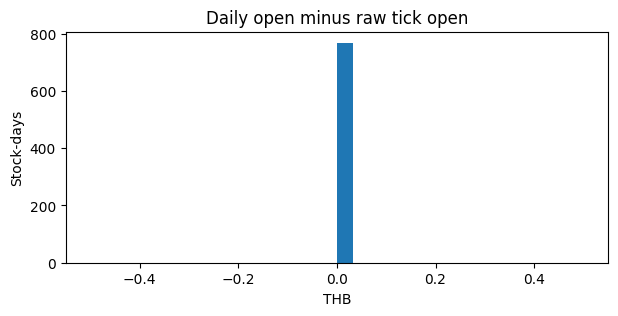

In [3]:
p=pd.read_csv(out/'daily_tick_reconciliation.csv')
t=pd.read_csv(out/'tick_session_alignment.csv')
display(pd.DataFrame([{'stock_days':len(p),'all_OHLC_match':int(p.all_ohlc_match.sum()),
 'missing_open_auction':int((~p.auction_open).sum()),'missing_close_auction':int((~p.auction_close).sum()),
 'globally_sorted_tick_files':int(t.globally_monotonic.sum()),'tick_files':len(t)}]))
fig,ax=plt.subplots(figsize=(7,3));ax.hist(p.open_difference,bins=30);ax.set(title='Daily open minus raw tick open',xlabel='THB',ylabel='Stock-days');plt.show()

## 4. Tick ladder and slippage uncertainty

The local daily model and native practice engine share the same ladder. That agreement does not establish that adjusted historical opens were executable at the corresponding tick levels.

In [4]:
ladder=pd.read_csv(out/'tick_size_validation.csv')
display(ladder)
assert (ladder.daily_tick==ladder.native_tick).all()

,price,daily_tick,native_tick
0,1.99,0.01,0.01
1,2.00,0.02,0.02
2,4.99,0.02,0.02
3,5.00,0.05,0.05
4,9.99,0.05,0.05
5,10.00,0.10,0.10
6,24.99,0.10,0.10
7,25.00,0.25,0.25
8,99.99,0.25,0.25
9,100.00,0.50,0.50


## 5. Cost decomposition across A–E

The gross-return proxy adds booked costs back to final NAV. It is not a separate zero-cost portfolio path. Scenario comparisons below rerun A under changed costs and preserve the signal decision rule.

,strategy,gross_return_proxy,mean_net,mean_excess,mean_turnover,commission_thb,vat_thb,slippage_thb,total_explicit_cost_thb
0,A,0.0195,-0.0017,-0.0090,2.7940,43935.4222,3075.4796,164589.5833,211600.4851
1,B,0.0173,-0.0049,-0.0122,2.9861,46950.9327,3286.5653,172416.8333,222654.3313
2,C,0.0183,-0.0030,-0.0103,2.8407,44669.7868,3126.8851,165395.0417,213191.7135
3,D,0.0157,-0.0071,-0.0143,3.0873,48539.7735,3397.7841,175832.8750,227770.4326
4,E,0.0193,0.0045,-0.0027,1.9257,30301.7217,2121.1205,115492.2917,147915.1339


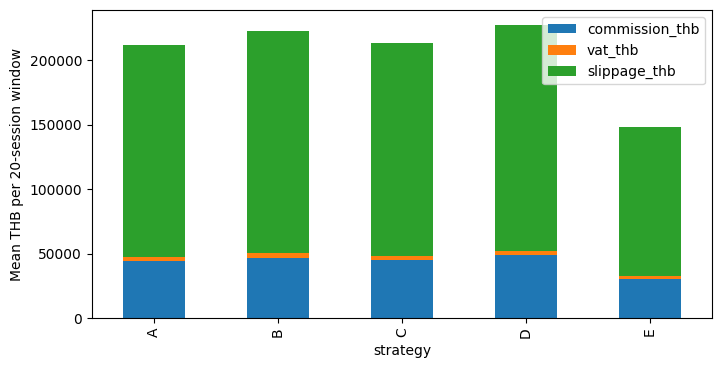

In [5]:
sc=pd.read_csv(out/'strategy_cost_summary.csv')
display(sc[['strategy','gross_return_proxy','mean_net','mean_excess','mean_turnover',
            'commission_thb','vat_thb','slippage_thb','total_explicit_cost_thb']].round(4))
sc.set_index('strategy')[['commission_thb','vat_thb','slippage_thb']].plot.bar(stacked=True,figsize=(8,4),ylabel='Mean THB per 20-session window');plt.show()

## 6. Matched execution scenarios for A

Cost-free A is diagnostic. Commission, VAT, adverse ticks, the participation cap, and half-fill sensitivities are tested with distinct portfolio paths. The last two are execution assumptions, not observed IOC outcomes.

In [6]:
c=pd.read_csv(out/'cost_summary.csv').set_index('experiment')
display(c[['mean_excess','mean_net','mean_turnover','mean_cost_pct','mean_roundtrips','common_pass','best_alpha_pass']].round(5))
direct=c.loc['one_tick','mean_cost_pct']; gap=c.loc['zero','mean_excess']-c.loc['one_tick','mean_excess']
display(pd.DataFrame([{'zero_to_one_tick_gap':gap,'booked_cost_fraction':direct,
                       'path_and_sizing_residual':gap-direct}]))
assert abs(c.loc['one_tick','mean_excess']+0.008990066405743463)<1e-10

,mean_excess,mean_net,mean_turnover,mean_cost_pct,mean_roundtrips,common_pass,best_alpha_pass
experiment,,,,,,,
commission,0.00779,0.01508,2.80575,0.00441,9.20833,3,2
commission_vat,0.00748,0.01477,2.80566,0.00471,9.20833,3,2
half_fills,-0.00808,-0.00079,1.48906,0.01131,1.25000,0,0
one_tick,-0.00899,-0.00171,2.79395,0.02116,9.00000,2,2
positive_momentum,-0.00896,-0.00168,2.79674,0.02123,9.00000,2,2
rebalance_every_10,0.00106,0.00835,1.58395,0.01203,3.00000,0,0
two_ticks,-0.02536,-0.01808,2.78386,0.03749,8.91667,0,0
unconstrained_cap,-0.00873,-0.00145,2.83989,0.02151,9.12500,2,2
zero,0.01220,0.01948,2.80867,0.00000,9.16667,5,3


,zero_to_one_tick_gap,booked_cost_fraction,path_and_sizing_residual
0,0.021189,0.02116,0.000029


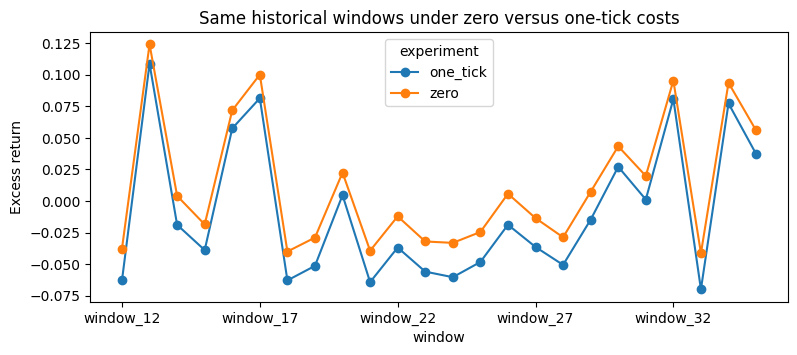

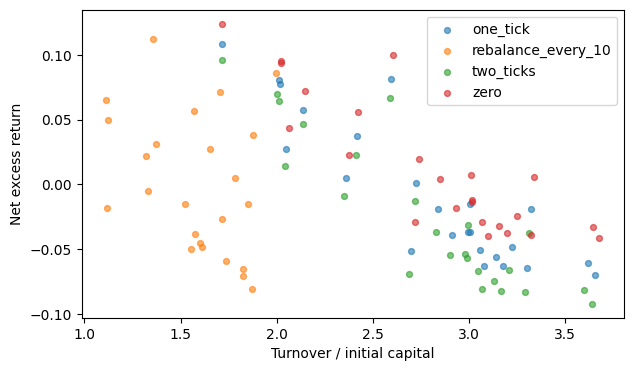

In [7]:
w=pd.read_csv(out/'cost_windows.csv')
pair=w[w.experiment.isin(['zero','one_tick'])].pivot(index='window',columns='experiment',values='excess_return')
pair.plot(figsize=(9,3.5),marker='o',ylabel='Excess return',title='Same historical windows under zero versus one-tick costs');plt.show()
fig,ax=plt.subplots(figsize=(7,4))
for label,g in w.groupby('experiment'):
    if label in ['zero','one_tick','two_ticks','rebalance_every_10']:
        ax.scatter(g.turnover,g.excess_return,s=18,alpha=.6,label=label)
ax.legend();ax.set(xlabel='Turnover / initial capital',ylabel='Net excess return');plt.show()

## 7. Break-even gross alpha

At the observed turnover and execution mix, required pre-cost alpha is approximately the booked cost fraction. This is a cost hurdle, not evidence that the signal can generate it.

In [8]:
unit_cost=direct/c.loc['one_tick','mean_turnover']
display(pd.DataFrame({'turnover_multiple':[1,2,3],
                      'approx_required_alpha':[unit_cost*x for x in [1,2,3]]}))
print('Observed no-cost mean excess:',round(c.loc['zero','mean_excess']*100,3),'%')

,turnover_multiple,approx_required_alpha
0,1,0.007574
1,2,0.015147
2,3,0.022721


Observed no-cost mean excess: 1.22 %


## 8. Native practice simulator on 16 tick sessions

A single real-tick buy verifies fee/cash arithmetic. The signal-driven 16-session replay uses frozen A decisions, waits for observed opposing tick volume, and submits Market orders on the first eligible chronological tick. The matched daily replay uses next-open modeled fills. This is neither an official Market-to-Limit IOC test nor a complete 20-session competition result.

,sessions,rebalance_sessions,attempted_orders,filled_orders,ending_nav,daily_model_ending_nav,ending_nav_difference,ending_cash,completed_fifo_lots,daily_model_completed_fifo_lots,scope
0,16,4,30,29,9.472515e+06,9.511308e+06,-38793.718459,1.952576e+06,9,10,16-session native practice replay using frozen...


Single-order native cash error (THB): -8.149072527885437e-10


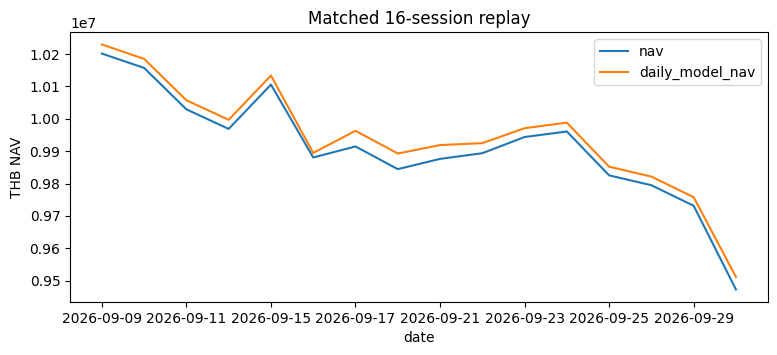

,attempts,fills
side,,
Buy,18,17
Sell,12,12


In [9]:
probe=json.loads((out/'native_probe.json').read_text())
ns=json.loads((out/'native_strategy_summary.json').read_text())
display(pd.DataFrame([ns]))
print('Single-order native cash error (THB):',probe['cash_delta_error'])
nd=pd.read_csv(out/'native_strategy_daily.csv').set_index('date')
nd[['nav','daily_model_nav']].plot(figsize=(9,3.5),ylabel='THB NAV',title='Matched 16-session replay');plt.show()
display(pd.read_csv(out/'native_strategy_orders.csv').groupby('side').agg(attempts=('filled','size'),fills=('filled',lambda x:int((x>0).sum()))))

## 9. Momentum selection and future returns

Future returns are diagnostics measured after the decision, not inputs to that decision. Observations overlap and share market regimes. Any selected-versus-unselected difference is not independent out-of-sample alpha.

,selected_A_observations,nonpositive_momentum,selected_forward_mean,unselected_forward_mean
0,576,4,0.006134,0.000781


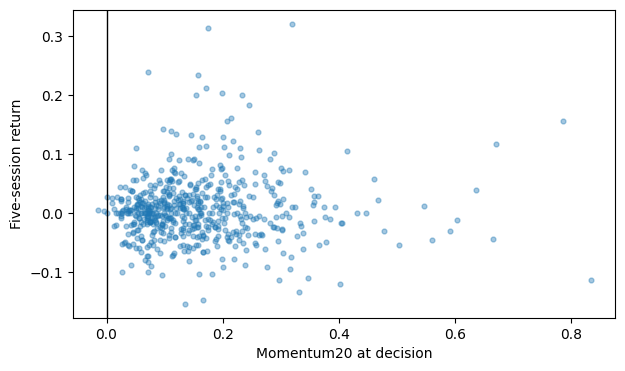

In [10]:
m=pd.read_csv(out/'momentum_selection.csv')
u=pd.read_csv(out/'momentum_forward_universe.csv')
a=m[m.strategy=='A']
display(pd.DataFrame([{'selected_A_observations':len(a),'nonpositive_momentum':int((a.momentum20<=0).sum()),
 'selected_forward_mean':u[u.selected_A].forward_5_session_return.mean(),
 'unselected_forward_mean':u[~u.selected_A].forward_5_session_return.mean()}]))
fig,ax=plt.subplots(figsize=(7,4));ax.scatter(a.momentum20,a.forward_5_session_return,s=12,alpha=.4)
ax.axvline(0,color='black',lw=1);ax.set(xlabel='Momentum20 at decision',ylabel='Five-session return');plt.show()

## 10. Turnover, FIFO duration, and eligibility

Actual filled orders distinguish new entries, additions, reductions, and full exits. The frozen records do not identify every exit reason. Holding-duration bins include only completed original FIFO lots, so they have exit-selection bias. Award eligibility is a gate, distinct from performance ranking.

,strategy,cause,notional,commission,vat,slippage
0,A,add_to_holding,24960127.0,39393.04,2757.51,130981.0
1,A,full_exit,213775735.0,333641.77,23354.92,1265056.0
2,A,new_entry,402994095.0,636440.79,44550.86,2382206.0
3,A,reduce_holding,28818107.0,44974.53,3148.22,171907.0


,duration_bin,lots,mean_pnl,win_rate
0,0-7 days,123,-38293.10,0.23
1,8-14 days,47,-27292.46,0.23
2,15-30 days,46,-14626.97,0.35
3,31+ days,0,0.00,0.00


,drawdown_pass,roundtrip_pass,exposure_pass,payoff_pass,nonnegative_return,nonnegative_excess
strategy,,,,,,
A,10,1,0,21,15,15
B,9,1,0,21,16,16
C,11,1,0,20,14,15
D,11,1,0,20,16,15
E,9,11,0,21,15,14


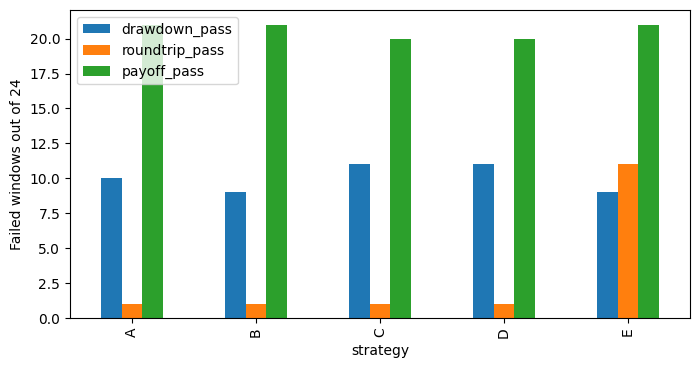

In [11]:
cause=pd.read_csv(out/'turnover_cause_summary.csv')
display(cause[cause.strategy=='A'].round(2))
dur=pd.read_csv(out/'holding_duration_diagnostics.csv')
display(dur.round(2))
fails=pd.read_csv(out/'eligibility_failures.csv').set_index('strategy').loc[list('ABCDE')]
display(fails)
fails[['drawdown_pass','roundtrip_pass','payoff_pass']].plot.bar(figsize=(8,4),ylabel='Failed windows out of 24');plt.show()

## 11. Controlled hypotheses and decision

The positive-momentum filter barely changes A. Ten-session rebalancing reduces costs but collapses completed FIFO lots and yields no Best Alpha eligible windows. The 24 windows have already been inspected. Without historical executable prices, official IOC behavior, and fresh chronological data, there is no defensible corrected-execution return estimate and no case for machine learning yet.

In [12]:
display(c.loc[['one_tick','positive_momentum','rebalance_every_10'],
 ['mean_excess','mean_turnover','mean_roundtrips','mean_exposure','best_alpha_pass']].round(5))
print('Decision: validate execution and historical adjustment data; then revisit factor discovery.')

,mean_excess,mean_turnover,mean_roundtrips,mean_exposure,best_alpha_pass
experiment,,,,,
one_tick,-0.00899,2.79395,9.0,0.79061,2
positive_momentum,-0.00896,2.79674,9.0,0.78853,2
rebalance_every_10,0.00106,1.58395,3.0,0.78534,0


Decision: validate execution and historical adjustment data; then revisit factor discovery.
